<div style="text-align:center; padding-top:20px;">
  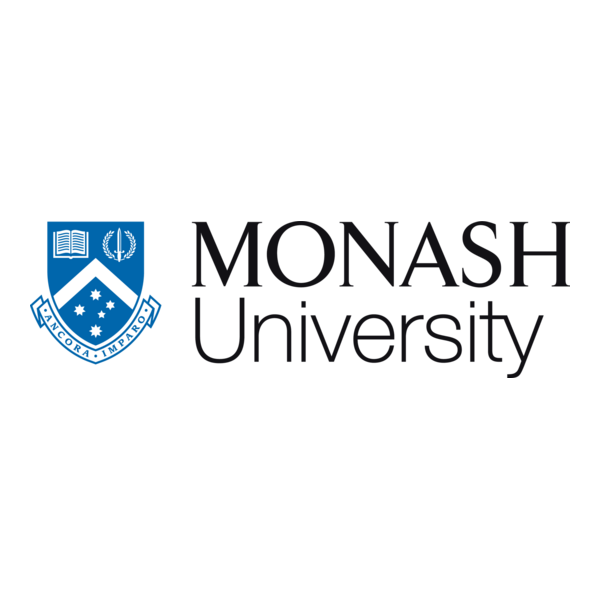
  <h1 style="color:#006dae; margin-top:24px;">FIT5196 Data Wrangling</h1>
  <h2>Assessment 2: Data Cleansing, Audit and Transformation</h2>
  <h3>Group030 — Technical Solution Notebook</h3>
  <p><strong>Semester 2, 2026</strong></p>
</div>

| Group member | Full name | Student ID |
|---:|---|---|
| 1 | **King Man Chan** | **36550779** |
| 2 | **Yinglin Fang** | **34814248** |
| 3 | **Sizhe Hong** | **35381949** |
| 4 | **Xinhang Ren** | **35134410** |
| 5 | **Guohou Zhang** | **35800275** |

> **Submission status.** Tasks 1 and 2 are implemented and validated. Task 3 is included as a complete analytical draft for group review.

# Executive summary

This notebook presents a reproducible workflow for cleansing three distinct Group030 order batches. The missing batch contains 80 omissions, the dirty batch contains 80 field-level inconsistencies, and the outlier batch contains anomalous delivery charges. The workflow preserves all 500 IDs in the missing and dirty outputs and removes 24 conditionally anomalous rows from the outlier output, leaving 476 retained orders.

Current product prices are inferred from reliable shopping-cart equations. Four season-specific linear delivery models are evaluated on held-out observations before being used for missing-value recovery, dirty-field diagnosis and residual-based outlier detection. Every imputation, repair and row removal is recorded in a 184-row field-level audit log. Read-back validation confirms exact schemas, ID rules, published business relationships, preservation of valid values and agreement between actual output differences and the audit log.

The final analytical section combines the 1,476 retained orders into 471 customer profiles and compares original values, z-score standardisation, min-max scaling and nonlinear transformations for possible future distance-based exploratory segmentation. No clustering model is fitted.

# Contents and assessment mapping

1. [Reproducibility and configuration](#0-reproducibility-and-configuration)  
2. [Initial investigation and evidence selection](#1-initial-investigation-and-evidence-selection)  
3. [Shared business rules and learned relationships](#2-shared-business-rules-and-learned-relationships)  
4. [Missing-data recovery](#3-missing-data-recovery)  
5. [Dirty-data diagnosis and repair](#4-dirty-data-diagnosis-and-repair)  
6. [Delivery-charge outlier removal](#5-delivery-charge-outlier-removal)  
7. [Audit trail and final validation](#6-audit-trail-and-final-validation)  
8. [Customer profiling and transformation](#7-customer-profiling-and-transformation)  
9. [Reproducibility and submission checklist](#8-reproducibility-and-submission-checklist)

| Assessment component | Primary evidence in this notebook |
|---|---|
| Task 1 — cleansing | Sections 1–5, including EDA, rules, held-out model evaluation, repairs and residual diagnostics |
| Task 2 — audit and validation | Section 6, including confidence definitions, audit reconciliation and read-back checks |
| Task 3 — customer profiling | Section 7, including aggregation, scaling, nonlinear comparisons and recommendations |

# 0. Reproducibility and configuration

The notebook is designed to run offline from either the repository root or the `notebooks/` directory. All paths and the group identifier are defined once below. Raw inputs are never overwritten; generated outputs are written to `outputs/`.

In [1]:
from pathlib import Path
import sys

GROUP_ID = "Group030"
WORKING_DIR = Path.cwd().resolve()
PROJECT_ROOT = (
    WORKING_DIR
    if (WORKING_DIR / "data" / "raw").exists()
    else WORKING_DIR.parent
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "data" / "raw" / f"{GROUP_ID}_A2"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DIRTY_INPUT = DATA_DIR / f"{GROUP_ID}_dirty_data.csv"
MISSING_INPUT = DATA_DIR / f"{GROUP_ID}_missing_data.csv"
OUTLIER_INPUT = DATA_DIR / f"{GROUP_ID}_outlier_data.csv"
WAREHOUSES_INPUT = DATA_DIR / "warehouses.csv"
RESOURCE_CONTRACT = DATA_DIR / "resource_contract.json"
NLTK_DATA_DIR = DATA_DIR / "resources" / "nltk_data"
MANIFEST_INPUT = DATA_DIR / "A2_manifest.json"

DIRTY_OUTPUT = OUTPUT_DIR / f"{GROUP_ID}_dirty_clean.csv"
MISSING_OUTPUT = OUTPUT_DIR / f"{GROUP_ID}_missing_clean.csv"
OUTLIER_OUTPUT = OUTPUT_DIR / f"{GROUP_ID}_outlier_clean.csv"
AUDIT_OUTPUT = OUTPUT_DIR / "audit_log.csv"

print("Project root:", PROJECT_ROOT)
print("Input directory:", DATA_DIR)
print("Output directory:", OUTPUT_DIR)

Project root: /home/user/FIT5196-A2
Input directory: /home/user/FIT5196-A2/data/raw/Group030_A2
Output directory: /home/user/FIT5196-A2/outputs


The configuration keeps marker-facing adjustments separate from cleansing logic. A marker can redirect the input and output roots without editing any repair rule, model or validation test.

## 0.1 Environment and dependencies

The implementation uses NumPy and pandas for data handling, scikit-learn for ordinary least-squares regression, Matplotlib for diagnostic graphics and NLTK 3.9.2 for the frozen VADER resource. A fixed random seed is used for every held-out split.

In [2]:
import hashlib
import json
import platform

import matplotlib
import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler

from src.dirty_cleaning import clean_dirty_batch
from src.missing_cleaning import (
    MODEL_FEATURES,
    clean_missing_batch,
    ORDER_COLUMNS,
    SEASON_BY_MONTH,
    calculate_order_price,
    fit_seasonal_models,
    infer_product_prices,
    nearest_warehouse,
    parse_cart,
    parse_order_date,
    setup_vader,
)
from src.outlier_cleaning import clean_outlier_batch

RANDOM_STATE = 5196
pd.set_option("display.max_columns", 30)
plt.style.use("seaborn-v0_8-whitegrid")

In [3]:
environment = pd.DataFrame(
    {
        "component": ["Python", "pandas", "NumPy", "scikit-learn", "Matplotlib", "NLTK"],
        "version": [
            platform.python_version(),
            pd.__version__,
            np.__version__,
            sklearn.__version__,
            matplotlib.__version__,
            nltk.__version__,
        ],
    }
)
display(environment)

,component,version
0,Python,3.12.3
1,pandas,3.0.5
2,NumPy,2.5.1
3,scikit-learn,1.9.0
4,Matplotlib,3.11.1
5,NLTK,3.9.2


Version reporting makes the submitted run auditable. Exact package versions are also recorded in `requirements.txt` after the final clean-environment execution.

## 0.2 Input integrity and frozen resource checks

The allocated manifest provides the expected SHA-256 hash for every supplied file. Verifying these hashes before analysis establishes that the workflow is operating on the unmodified Group030 package.

In [4]:
manifest = json.loads(MANIFEST_INPUT.read_text(encoding="utf-8"))
manifest_checks = []

for entry in manifest["files"]:
    path = DATA_DIR / entry["path"]
    actual_hash = hashlib.sha256(path.read_bytes()).hexdigest()
    manifest_checks.append(
        {
            "path": entry["path"],
            "exists": path.exists(),
            "expected_sha256": entry["sha256"],
            "actual_sha256": actual_hash,
            "passed": actual_hash == entry["sha256"],
        }
    )

manifest_check_table = pd.DataFrame(manifest_checks)
display(manifest_check_table[["path", "exists", "passed"]])
assert manifest_check_table["passed"].all()

,path,exists,passed
0,Group030_dirty_data.csv,True,True
1,Group030_missing_data.csv,True,True
2,Group030_outlier_data.csv,True,True
3,README.md,True,True
4,input_manifest.csv,True,True
5,resource_contract.json,True,True
6,resources/nltk_data/sentiment/vader_lexicon.zip,True,True
7,warehouses.csv,True,True


In [5]:
resource_contract = json.loads(RESOURCE_CONTRACT.read_text(encoding="utf-8"))
lexicon_path = DATA_DIR / resource_contract["vader_lexicon_relative_path"]
lexicon_hash = hashlib.sha256(lexicon_path.read_bytes()).hexdigest()

resource_check = pd.DataFrame(
    {
        "check": ["Required NLTK version", "Frozen lexicon SHA-256"],
        "expected": [resource_contract["nltk_version"], resource_contract["vader_lexicon_sha256"]],
        "observed": [nltk.__version__, lexicon_hash],
    }
)
resource_check["passed"] = resource_check["expected"] == resource_check["observed"]
display(resource_check)
assert resource_check["passed"].all()

,check,expected,observed,passed
0,Required NLTK version,3.9.2,3.9.2,True
1,Frozen lexicon SHA-256,8adba4294eef3964d820bf655e37e61bdc3a341994356a...,8adba4294eef3964d820bf655e37e61bdc3a341994356a...,True


All allocated-file and VADER checks pass. The workflow does not download substitute resources, satisfying the offline reproducibility requirement.

# 1. Initial investigation and evidence selection

The three CSVs are separate order batches with the same 16-column schema. They are not alternative versions of the same orders. Source-batch identity is retained throughout diagnosis and is added explicitly when the cleaned outputs are later concatenated for customer profiling.

In [6]:
read_options = {"dtype": {"order_id": "string", "customer_id": "string"}}
dirty_raw = pd.read_csv(DIRTY_INPUT, **read_options)
missing_raw = pd.read_csv(MISSING_INPUT, **read_options)
outlier_raw = pd.read_csv(OUTLIER_INPUT, **read_options)
warehouses = pd.read_csv(WAREHOUSES_INPUT)

raw_batches = {
    "dirty": dirty_raw,
    "missing": missing_raw,
    "outlier": outlier_raw,
}

batch_overview = pd.DataFrame(
    [
        {
            "batch": name,
            "rows": len(frame),
            "columns": frame.shape[1],
            "unique_orders": frame["order_id"].nunique(),
            "customers": frame["customer_id"].nunique(),
            "missing_cells": int(frame.isna().sum().sum()),
        }
        for name, frame in raw_batches.items()
    ]
)
display(batch_overview)

,batch,rows,columns,unique_orders,customers,missing_cells
0,dirty,500,16,500,321,0
1,missing,500,16,500,323,80
2,outlier,500,16,500,318,0


Each batch has 500 rows and 16 columns. Order IDs are unique within each file; only the missing batch contains empty CSV fields. The different customer counts reflect repeated customers across orders rather than duplicate order records.

## 1.1 Schema, types and key integrity

Schema equality and identifier checks are performed before any data-dependent calculation. A schema discrepancy would make the required output inaccessible to the marker and therefore stops the workflow.

In [7]:
schema_check = pd.DataFrame(
    {
        name: pd.Series(frame.dtypes.astype(str), index=frame.columns)
        for name, frame in raw_batches.items()
    }
)
display(schema_check)

assert all(list(frame.columns) == ORDER_COLUMNS for frame in raw_batches.values())
assert all(frame["order_id"].is_unique for frame in raw_batches.values())

combined_raw_ids = pd.concat(
    [frame[["order_id"]].assign(source_batch=name) for name, frame in raw_batches.items()],
    ignore_index=True,
)
print("Distinct IDs across all raw batches:", combined_raw_ids["order_id"].nunique())
assert combined_raw_ids["order_id"].is_unique

,dirty,missing,outlier
order_id,string,string,string
customer_id,string,string,string
date,str,str,str
nearest_warehouse,str,str,str
shopping_cart,str,str,str
order_price,float64,float64,float64
delivery_charges,float64,float64,float64
customer_lat,float64,float64,float64
customer_long,float64,float64,float64
coupon_discount,int64,int64,int64


Distinct IDs across all raw batches: 1500


The 1,500 source rows contain 1,500 distinct order IDs. This confirms that cleaning must preserve three separate batches rather than merge records by order ID.

## 1.2 Missingness diagnosis

Missingness is reported by field and batch. The heat map below shows affected cells only; it does not treat sentinel review text as missing.

,dirty,missing,outlier
field,,,
nearest_warehouse,0,10,0
order_price,0,10,0
delivery_charges,0,10,0
order_total,0,10,0
season,0,10,0
is_expedited_delivery,0,10,0
distance_to_nearest_warehouse,0,10,0
is_happy_customer,0,10,0


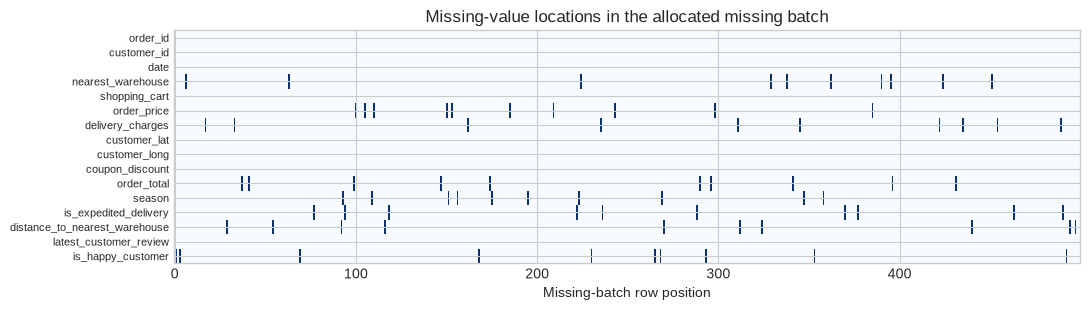

In [8]:
missingness = pd.DataFrame(
    {name: frame.isna().sum() for name, frame in raw_batches.items()}
)
missingness.index.name = "field"
display(missingness.loc[missingness.sum(axis=1) > 0])

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.imshow(missing_raw.isna().T, aspect="auto", cmap="Blues", interpolation="nearest")
ax.set_yticks(range(len(missing_raw.columns)))
ax.set_yticklabels(missing_raw.columns, fontsize=8)
ax.set_xlabel("Missing-batch row position")
ax.set_title("Missing-value locations in the allocated missing batch")
plt.tight_layout()
plt.show()

There are 80 omissions across 80 different missing-batch rows. Eight fields each contain ten omissions, and no row is missing more than one field. The batch guarantee makes every observed value in these rows reliable evidence for reconstructing the single omitted field.

## 1.3 Categorical values and numeric distributions

Unexpected labels, Boolean frequencies and numeric ranges provide early evidence of dirty fields and potential outliers. At this stage, unusual values are flagged rather than automatically changed.

In [9]:
categorical_summary = []
for batch_name, frame in raw_batches.items():
    for column in ["nearest_warehouse", "season", "is_expedited_delivery", "is_happy_customer"]:
        categorical_summary.append(
            {
                "batch": batch_name,
                "field": column,
                "value_counts": frame[column].value_counts(dropna=False).to_dict(),
            }
        )
display(pd.DataFrame(categorical_summary))

,batch,field,value_counts
0,dirty,nearest_warehouse,"{'Thompson': 218, 'Bakers': 213, 'Nickolson': ..."
1,dirty,season,"{'Autumn': 142, 'Winter': 123, 'Summer': 121, ..."
2,dirty,is_expedited_delivery,"{False: 408, True: 92}"
3,dirty,is_happy_customer,"{True: 423, False: 77}"
4,missing,nearest_warehouse,"{'Bakers': 222, 'Thompson': 191, 'Nickolson': ..."
5,missing,season,"{'Summer': 133, 'Winter': 125, 'Spring': 121, ..."
6,missing,is_expedited_delivery,"{False: 396, True: 94, nan: 10}"
7,missing,is_happy_customer,"{True: 406, False: 84, nan: 10}"
8,outlier,nearest_warehouse,"{'Bakers': 221, 'Thompson': 214, 'Nickolson': 65}"
9,outlier,season,"{'Autumn': 135, 'Summer': 133, 'Winter': 119, ..."


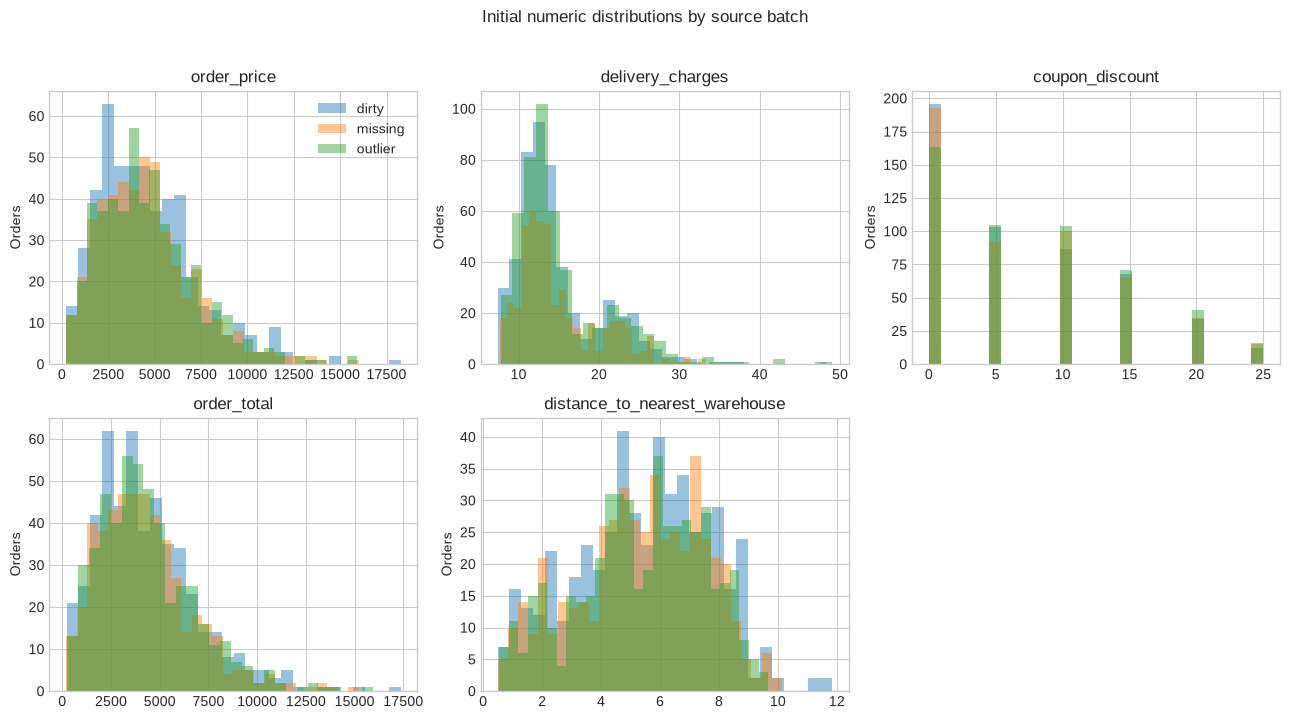

In [10]:
selected_numeric = [
    "order_price",
    "delivery_charges",
    "coupon_discount",
    "order_total",
    "distance_to_nearest_warehouse",
]

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
axes = axes.flatten()
for axis, column in zip(axes, selected_numeric):
    for batch_name, frame in raw_batches.items():
        axis.hist(frame[column].dropna(), bins=28, alpha=0.45, label=batch_name)
    axis.set_title(column)
    axis.set_ylabel("Orders")
axes[0].legend()
axes[-1].axis("off")
plt.suptitle("Initial numeric distributions by source batch", y=1.02)
plt.tight_layout()
plt.show()

Raw charge magnitude alone cannot identify a delivery outlier because distance, season, expedited status and happiness affect the expected charge. The overlap in raw distributions motivates conditional residual analysis rather than a simple high-value cutoff.

## 1.4 Location evidence

Melbourne customer coordinates should cluster near the three supplied warehouses. Plotting raw coordinates independently reveals sign errors without using any order-ID pattern.

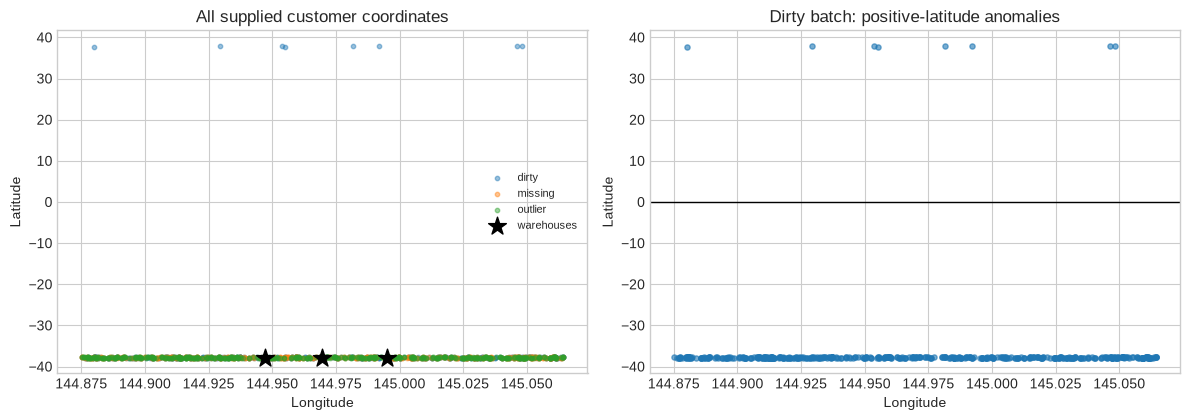

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))

for batch_name, frame in raw_batches.items():
    axes[0].scatter(frame["customer_long"], frame["customer_lat"], s=10, alpha=0.45, label=batch_name)
axes[0].scatter(warehouses["longitude"], warehouses["latitude"], marker="*", s=180, c="black", label="warehouses")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
axes[0].set_title("All supplied customer coordinates")
axes[0].legend(fontsize=8)

axes[1].scatter(dirty_raw["customer_long"], dirty_raw["customer_lat"], s=14, alpha=0.6)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
axes[1].set_title("Dirty batch: positive-latitude anomalies")

plt.tight_layout()
plt.show()

Eight dirty-batch latitudes appear in the northern hemisphere while warehouse coordinates and all reliable customers are in Melbourne. This is independent evidence that the latitude sign—not the warehouse or distance—is the root error in those rows.

## 1.5 Evidence-selection policy

| Evidence source | Appropriate use | Exclusion or safeguard |
|---|---|---|
| Observed missing-batch values | Product prices and delivery-model fitting | Exclude rows missing the response or any required predictor |
| Dirty batch | Rule-based repair after independent diagnosis | Do not use unresolved fields to train a model |
| Outlier batch | Residual-based target for anomaly decisions | Do not train the delivery model on potentially anomalous charges |
| `warehouses.csv` | Warehouse names and coordinates | Treated as the supplied correct reference |
| Frozen VADER resource | Happiness reconstruction and checks | Verify NLTK version and SHA-256; no downloads or text rewriting |

This policy prevents contaminated targets, circular repairs and reliance on another group or historical A1 prices.

# 2. Shared business rules and learned relationships

Shared functions are defined in submitted Python modules and imported above. The following cells expose their inputs, equations, diagnostics and interpretations so the notebook remains an understandable technical report rather than a sequence of opaque function calls.

## 2.1 Shopping-cart parsing and product inventory

Each shopping cart is parsed with `json.loads`. Every entry must contain a product string and a positive integer quantity. The current product catalogue is derived from the A2 carts; no A1 price list is used.

In [12]:
parsed_carts = missing_raw["shopping_cart"].map(parse_cart)
products = sorted(
    {
        item["product"]
        for cart in parsed_carts
        for item in cart
    }
)
cart_structure_summary = pd.DataFrame(
    {
        "metric": ["valid carts", "distinct products", "minimum cart lines", "maximum cart lines"],
        "value": [len(parsed_carts), len(products), parsed_carts.map(len).min(), parsed_carts.map(len).max()],
    }
)
display(cart_structure_summary)
display(pd.DataFrame({"product": products}))

,metric,value
0,valid carts,500
1,distinct products,12
2,minimum cart lines,1
3,maximum cart lines,5


,product
0,Candle Arc 420
1,Candle Bloom 316
2,Candle Bloom 838
3,Candle Edge 572
4,Candle Lumen 778
5,Candle Shift 232
6,Vela Atlas 863
7,Vela Echo 547
8,Vela Echo 583
9,Vela Halo 137


Twelve products occur in valid JSON carts containing one to five distinct line items. Product names and quantities are guaranteed complete and are preserved exactly.

## 2.2 Current-price inference

For order \(j\), the published relationship is

\[
y_j = \sum_{i=1}^{12} q_{ji}p_i,
\]

where \(q_{ji}\) is the quantity of product \(i\), \(p_i\) is its current unit price and \(y_j\) is the observed order price. Across orders this becomes \(Qp=y\). Full column rank is required to identify a unique 12-price vector.

In [13]:
price_map, price_diagnostics = infer_product_prices(missing_raw)
price_table = pd.DataFrame(
    [{"product": product, "unit_price_AUD": value} for product, value in price_map.items()]
)

display(price_diagnostics)
display(price_table)

,observed_equations,training_equations,heldout_equations,training_rank,product_count,heldout_max_absolute_error,all_equations_max_absolute_error
0,490,392,98,12,12,0.0,0.0


,product,unit_price_AUD
0,Candle Arc 420,2742.91
1,Candle Bloom 316,698.58
2,Candle Bloom 838,1098.41
3,Candle Edge 572,1340.90
4,Candle Lumen 778,1371.48
5,Candle Shift 232,801.49
6,Vela Atlas 863,3657.74
7,Vela Echo 547,899.34
8,Vela Echo 583,1072.62
9,Vela Halo 137,769.91


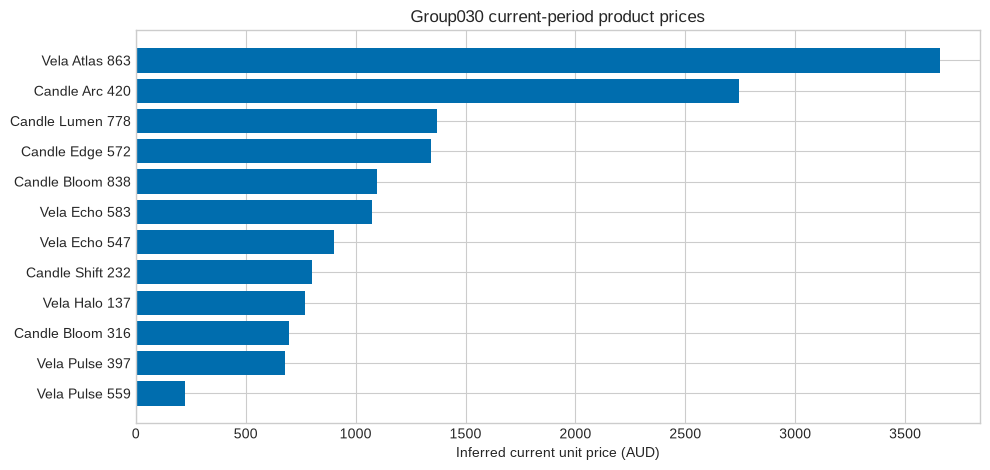

In [14]:
fig, ax = plt.subplots(figsize=(10, 4.8))
ordered_prices = price_table.sort_values("unit_price_AUD")
ax.barh(ordered_prices["product"], ordered_prices["unit_price_AUD"], color="#006dae")
ax.set_xlabel("Inferred current unit price (AUD)")
ax.set_title("Group030 current-period product prices")
plt.tight_layout()
plt.show()

The 392 estimation equations retain rank 12. All 98 held-out equations and all 490 observed equations have maximum absolute error AUD 0.00 after the specified item-level rounding. This supports using the inferred prices to reconstruct missing or dirty `order_price` values.

## 2.3 Dates, geography and sentiment

Dates use year-first interpretation when the year is first and day-first interpretation for slash-formatted day/month/year values. Australian seasons are derived from month. Haversine distance uses an Earth radius of 6,371 km and is reconstructed to four decimals.

In [15]:
example_date = "01/03/2019"
parsed_example = parse_order_date(example_date)
example_warehouse, example_distance = nearest_warehouse(
    missing_raw.loc[0, "customer_lat"],
    missing_raw.loc[0, "customer_long"],
    warehouses,
)

rule_examples = pd.DataFrame(
    {
        "rule": ["day-first date", "derived season", "nearest warehouse", "Haversine distance (km)"],
        "example_result": [
            parsed_example.strftime("%Y-%m-%d"),
            SEASON_BY_MONTH[parsed_example.month],
            example_warehouse,
            round(example_distance, 4),
        ],
    }
)
display(rule_examples)

,rule,example_result
0,day-first date,2019-03-01
1,derived season,Autumn
2,nearest warehouse,Bakers
3,Haversine distance (km),7.1302


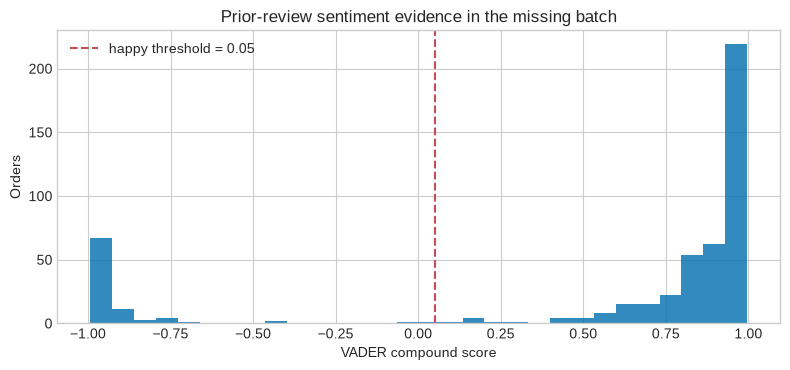

In [16]:
# This call re-verifies both the local lexicon checksum and NLTK version.
vader_analyzer = setup_vader(RESOURCE_CONTRACT, NLTK_DATA_DIR)

review_scores = missing_raw["latest_customer_review"].map(
    lambda text: 0.0 if text == "No review submitted" else vader_analyzer.polarity_scores(text)["compound"]
)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(review_scores, bins=30, color="#006dae", alpha=0.8)
ax.axvline(0.05, color="#c44e52", linestyle="--", label="happy threshold = 0.05")
ax.set_xlabel("VADER compound score")
ax.set_ylabel("Orders")
ax.set_title("Prior-review sentiment evidence in the missing batch")
ax.legend()
plt.tight_layout()
plt.show()

Review text is scored exactly as supplied. `is_happy_customer` is True when the compound score is at least 0.05; the exact `No review submitted` sentinel is treated as True without replacing or generating review text.

## 2.4 Seasonal delivery-charge regression

A separate ordinary least-squares model is fitted for each season:

\[
\widehat{delivery} = eta_0 + eta_1(distance) + eta_2(expedited) + eta_3(happy).
\]

Booleans are encoded consistently as 0/1. Scaling is unnecessary because the goal is to recover the specified relationship in its original units and preserve coefficient interpretability.

In [17]:
seasonal_models, model_diagnostics = fit_seasonal_models(missing_raw)
model_display = model_diagnostics.copy()
for column in [
    "heldout_r_squared",
    "heldout_mae",
    "intercept",
    "distance_coefficient",
    "expedited_coefficient",
    "happy_coefficient",
]:
    model_display[column] = model_display[column].round(6)
display(model_display)

,season,reliable_observations,training_observations,heldout_observations,heldout_r_squared,heldout_mae,intercept,distance_coefficient,expedited_coefficient,happy_coefficient
0,Summer,125,100,25,1.000000,0.002419,9.999191,0.700247,9.999835,-2.000375
1,Autumn,103,82,21,1.000000,0.002164,9.996941,0.780000,11.000129,-2.996824
2,Winter,116,92,24,1.000000,0.002822,14.001254,0.849878,13.000287,-4.000432
3,Spring,106,84,22,0.999999,0.002197,9.999172,0.730389,10.499802,-2.500837


### Held-out evaluation

Within each season, an 80/20 split with `random_state=5196` is used. Metrics are calculated on observations that were not used to fit the evaluation model. After evaluation, the operational model is refitted on all reliable observations from that season.

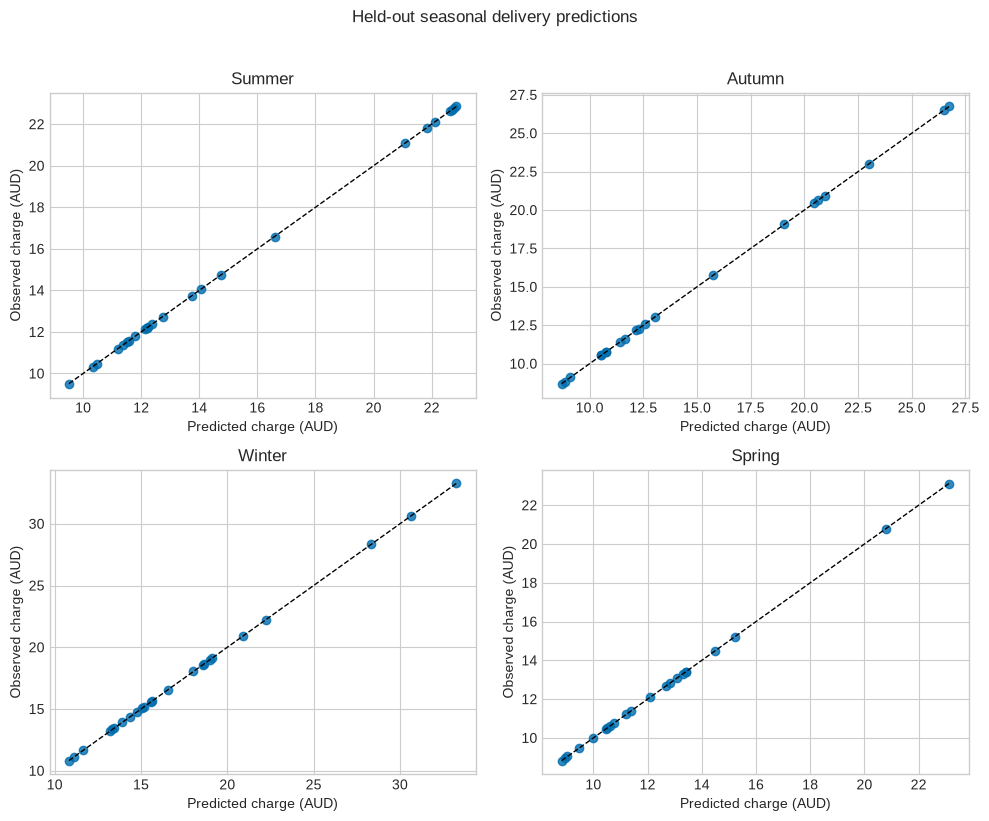

,season,training_n,heldout_n,heldout_R2,heldout_MAE_AUD,heldout_max_abs_residual
0,Summer,100,25,1.000000,0.002419,0.005385
1,Autumn,82,21,1.000000,0.002164,0.005942
2,Winter,92,24,1.000000,0.002822,0.005577
3,Spring,84,22,0.999999,0.002197,0.005915


In [18]:
reliable_delivery = missing_raw.dropna(
    subset=["season", "delivery_charges", *MODEL_FEATURES]
)
heldout_rows = []

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for axis, season in zip(axes.flatten(), ["Summer", "Autumn", "Winter", "Spring"]):
    season_rows = reliable_delivery.loc[reliable_delivery["season"] == season]
    X = season_rows[MODEL_FEATURES].astype(float)
    y = season_rows["delivery_charges"].astype(float)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=RANDOM_STATE
    )
    evaluation_model = LinearRegression().fit(X_train, y_train)
    predictions = evaluation_model.predict(X_test)

    heldout_rows.append(
        {
            "season": season,
            "training_n": len(X_train),
            "heldout_n": len(X_test),
            "heldout_R2": r2_score(y_test, predictions),
            "heldout_MAE_AUD": mean_absolute_error(y_test, predictions),
            "heldout_max_abs_residual": np.max(np.abs(y_test - predictions)),
        }
    )

    axis.scatter(predictions, y_test, alpha=0.8, color="#006dae")
    low = min(predictions.min(), y_test.min())
    high = max(predictions.max(), y_test.max())
    axis.plot([low, high], [low, high], "k--", linewidth=1)
    axis.set_title(season)
    axis.set_xlabel("Predicted charge (AUD)")
    axis.set_ylabel("Observed charge (AUD)")

plt.suptitle("Held-out seasonal delivery predictions", y=1.02)
plt.tight_layout()
plt.show()
heldout_evaluation = pd.DataFrame(heldout_rows)
display(heldout_evaluation.round(6))

Held-out \(R^2\) is at least 0.999999 and MAE is below AUD 0.003 in every season. `R²` measures the fraction of held-out charge variation explained by the model; MAE is the average absolute prediction error in Australian dollars. The near-perfect performance is plausible because the fictional charges were generated from a seasonal linear relationship, but residual and preservation checks are still required—high `R²` alone does not prove that every repair is correct.

# 3. Missing-data recovery

The missing batch contains omissions only; all observed values are guaranteed correct. Deterministic relationships are preferred. Regression is used only where no exact published calculation identifies the omitted field.

In [19]:
missing_counts = missing_raw.isna().sum().loc[lambda values: values > 0]
missing_diagnosis = missing_counts.rename("missing_values").to_frame()
missing_diagnosis["affected_rows"] = [missing_raw[column].isna().sum() for column in missing_diagnosis.index]
display(missing_diagnosis)
print("Rows with at least one omission:", int(missing_raw.isna().any(axis=1).sum()))
print("Maximum omissions in one row:", int(missing_raw.isna().sum(axis=1).max()))

,missing_values,affected_rows
nearest_warehouse,10,10
order_price,10,10
delivery_charges,10,10
order_total,10,10
season,10,10
is_expedited_delivery,10,10
distance_to_nearest_warehouse,10,10
is_happy_customer,10,10


Rows with at least one omission: 80
Maximum omissions in one row: 1


| Missing field | Recovery evidence |
|---|---|
| `season` | Published month-to-season mapping |
| `nearest_warehouse` | Minimum Haversine distance across all warehouses |
| `distance_to_nearest_warehouse` | Haversine distance to the nearest warehouse |
| `order_price` | Parsed cart and independently inferred unit prices |
| `order_total` | Published discount-plus-delivery formula |
| `is_happy_customer` | Frozen VADER threshold and sentinel rule |
| `delivery_charges` | Applicable evaluated seasonal regression |
| `is_expedited_delivery` | Compare model residuals under 0 and 1 |

In [20]:
missing_result = clean_missing_batch(
    missing_input=MISSING_INPUT,
    warehouses_input=WAREHOUSES_INPUT,
    resource_contract=RESOURCE_CONTRACT,
    nltk_data_dir=NLTK_DATA_DIR,
    missing_output=MISSING_OUTPUT,
    audit_output=AUDIT_OUTPUT,
)

display(missing_result.imputation_summary)

,field_name,confidence,imputed_values
0,delivery_charges,high,10
1,distance_to_nearest_warehouse,high,10
2,is_expedited_delivery,high,10
3,is_happy_customer,high,10
4,nearest_warehouse,high,10
5,order_price,high,10
6,order_total,high,10
7,season,high,10


The workflow reconstructs all 80 omissions and preserves every originally observed source value. Ten replacements are made in each of the eight fields.

## 3.1 Worked examples

The following examples are generated from the actual source, output and audit records rather than entered manually.

In [21]:
missing_examples = missing_result.audit.loc[
    missing_result.audit["record_key"].isin(["CORD000601", "CORD000518", "CORD000578"]),
    ["record_key", "field_name", "original_value", "corrected_value", "method", "evidence"],
]
display(missing_examples)

example_price = (
    price_map["Vela Echo 583"]
    + price_map["Candle Bloom 316"]
    + price_map["Vela Echo 547"]
    + price_map["Vela Pulse 559"]
)
example_calculations = pd.DataFrame(
    {
        "order_id": ["CORD000601", "CORD000518", "CORD000578"],
        "calculation": [
            f"1072.62 + 698.58 + 899.34 + 225.26 = {example_price:.2f}",
            "Winter model prediction from distance=8.0532, expedited=0, happy=1",
            "regular residual=0.0031 versus expedited residual=10.5029",
        ],
        "decision": ["order_price = 2895.80", "delivery_charges = 16.85", "expedited = False"],
    }
)
display(example_calculations)

,record_key,field_name,original_value,corrected_value,method,evidence
30,CORD000601,order_price,<MISSING>,2895.8,Sum of rounded quantity times inferred current...,M04: 490 observed equations; rank 12; held-out...
60,CORD000518,delivery_charges,<MISSING>,16.85,"Season-specific linear model using distance, e...","M07: Winter held-out R2=1.000000, MAE=0.0028"
70,CORD000578,is_expedited_delivery,<MISSING>,False,Choose 0/1 state with smaller seasonal-model a...,M08: regular residual=0.0031; expedited residu...


,order_id,calculation,decision
0,CORD000601,1072.62 + 698.58 + 899.34 + 225.26 = 2895.80,order_price = 2895.80
1,CORD000518,"Winter model prediction from distance=8.0532, ...",delivery_charges = 16.85
2,CORD000578,regular residual=0.0031 versus expedited resid...,expedited = False


CORD000601 demonstrates exact cart-price reconstruction. CORD000518 uses the evaluated Winter model and its observed total as a check. CORD000578 has a near-zero residual under non-expedited delivery and an approximately AUD 10.50 residual under expedited delivery, giving a clear Boolean decision.

## 3.2 Missing-output validation

The exported CSV is read back from disk before validation. Checks cover accessibility, schema, ID preservation, completeness, all published relationships, preservation of observed values and one-to-one audit reconciliation.

In [22]:
display(missing_result.validation)
assert missing_result.validation["passed"].all()

,check,observed_result,passed,interpretation
0,schema_and_column_order,"[order_id, customer_id, date, nearest_warehous...",True,Output must use the exact original 16-column s...
1,row_count,500,True,All missing-batch orders retained.
2,unique_order_ids,500,True,One row remains for each order.
3,preserved_order_id_set,"{'missing': 0, 'unexpected': 0}",True,No order IDs were lost or introduced.
4,required_completeness,0,True,No empty fields remain.
5,shopping_cart_structure,True,True,All carts are valid JSON arrays.
6,order_price_relationship,0.0,True,Cart equations reproduce order prices.
7,date_season_relationship,0,True,Dates map to Australian seasons.
8,nearest_warehouse_relationship,0,True,Nearest warehouse agrees with coordinates.
9,distance_relationship,0.0,True,Haversine distances agree to four decimals.


All missing-batch checks pass. Ten model-imputed charges produce at most a one-cent recomputation difference for a small number of already-valid observed totals. Those totals are correctly preserved rather than overwritten to force agreement with an estimate.

# 4. Dirty-data diagnosis and repair

A dirty row contains at most one intentional error. The workflow therefore diagnoses root fields from independent evidence and refuses competing repairs for a row. It does not use order-ID patterns or assume a fixed number of bad records.

## 4.1 Dependency-aware repair sequence

1. Parse and standardise the date, then independently derive season.  
2. Test whether coordinates are plausible for Melbourne before using them for warehouse or distance checks.  
3. Calculate nearest warehouse and Haversine distance from valid coordinates.  
4. Recalculate order price from the cart and validated unit prices.  
5. Recalculate happiness from the frozen VADER rule.  
6. For a failed total equation, use cart evidence and delivery residuals to isolate `order_price`, `delivery_charges` or `order_total`.  
7. For otherwise consistent rows, compare expedited = 0 and expedited = 1 residuals.

In [23]:
missing_reference = pd.read_csv(MISSING_INPUT, **read_options)
dirty_result = clean_dirty_batch(
    dirty_input=DIRTY_INPUT,
    missing_reference=missing_reference,
    warehouses_input=WAREHOUSES_INPUT,
    dirty_output=DIRTY_OUTPUT,
    audit_output=AUDIT_OUTPUT,
    prices=missing_result.price_map,
    models=missing_result.seasonal_models,
    analyzer=missing_result.vader_analyzer,
)

display(dirty_result.repair_summary)
print("Reliable model-residual limit used for dirty diagnosis:", dirty_result.reliable_model_residual_limit)

,field_name,confidence,repaired_values
0,customer_lat,high,8
1,date,high,8
2,delivery_charges,high,8
3,distance_to_nearest_warehouse,high,8
4,is_expedited_delivery,high,8
5,is_happy_customer,high,8
6,nearest_warehouse,high,8
7,order_price,high,8
8,order_total,high,8
9,season,high,8


Reliable model-residual limit used for dirty diagnosis: 0.015763976980162513


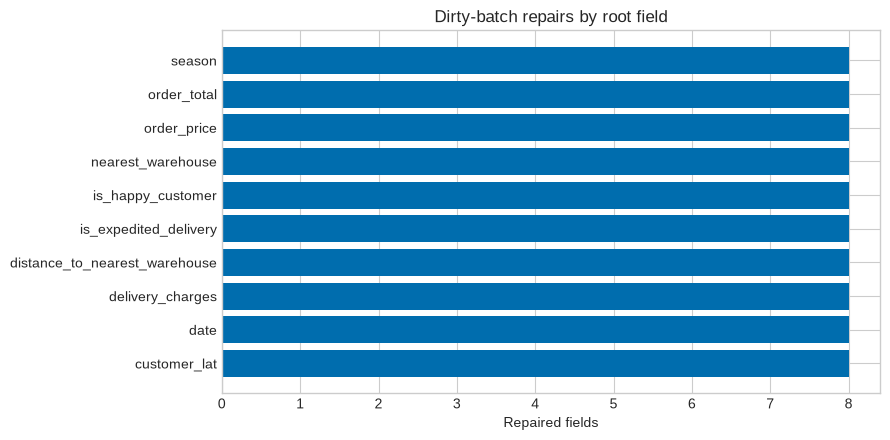

In [24]:
fig, ax = plt.subplots(figsize=(9, 4.5))
repair_plot = dirty_result.repair_summary.sort_values("repaired_values")
ax.barh(repair_plot["field_name"], repair_plot["repaired_values"], color="#006dae")
ax.set_xlabel("Repaired fields")
ax.set_title("Dirty-batch repairs by root field")
plt.tight_layout()
plt.show()

The rules identify 80 affected orders with exactly one repair each: eight repairs in each of ten field categories. This balanced count is an observed diagnostic result, not a detection assumption.

## 4.2 Worked examples and monetary isolation

For a valid row,

\[
order\_total = round(order\_price(1-discount/100)+delivery,2).
\]

When this relationship fails, independent cart-price and seasonal-model evidence determine which single monetary field is inconsistent.

In [25]:
dirty_example_ids = ["CORD000061", "CORD000044", "CORD000060", "CORD000100", "CORD000003"]
dirty_examples = dirty_result.dirty_audit.loc[
    dirty_result.dirty_audit["record_key"].isin(dirty_example_ids),
    ["record_key", "field_name", "original_value", "corrected_value", "method", "evidence"],
]
display(dirty_examples)

monetary_examples = pd.DataFrame(
    {
        "order_id": ["CORD000060", "CORD000100"],
        "published calculation": [
            "5940.94 - 5924.11 = 16.83",
            "round(2223.01 × (1 - 0.20) + 27.20, 2) = 1805.61",
        ],
        "isolated root error": ["delivery_charges", "order_total"],
    }
)
display(monetary_examples)

,record_key,field_name,original_value,corrected_value,method,evidence
3,CORD000044,distance_to_nearest_warehouse,11.5264,7.7764,Recalculate Haversine distance to the nearest ...,"D05: 6,371 km radius and four-decimal reconstr..."
7,CORD000061,customer_lat,37.840648,-37.840648,Restore Melbourne latitude sign while retainin...,D03: supplied warehouses and all reliable cust...
56,CORD000060,delivery_charges,24.08,16.83,"Back-calculate charge from validated total, pr...",D09: implied-charge model residual=0.0002; obs...
57,CORD000100,order_total,1897.11,1805.61,Recalculate total from independently validated...,D08: observed-charge model residual=0.0022; pu...
72,CORD000003,is_expedited_delivery,False,True,Choose 0/1 state with smaller seasonal-model a...,D10: current residual=9.9992; alternative resi...


,order_id,published calculation,isolated root error
0,CORD000060,5940.94 - 5924.11 = 16.83,delivery_charges
1,CORD000100,"round(2223.01 × (1 - 0.20) + 27.20, 2) = 1805.61",order_total


For CORD000060, the charge implied by independently valid price and total has model residual 0.0002, while the observed charge residual is 7.2502. The exact algebraic value 16.83 is therefore used instead of replacing the charge with a rounded model estimate. For CORD000003, flipping expedited status reduces residual from 9.9992 to 0.0006.

## 4.3 Dirty-output validation

In addition to all business relationships, validation derives actual input/output differences and checks that each affected order changes at most one field and each difference has exactly one audit record with the submitted corrected value.

In [26]:
display(dirty_result.validation)
assert dirty_result.validation["passed"].all()

,check,observed_result,passed,interpretation
0,schema_and_column_order,"[order_id, customer_id, date, nearest_warehous...",True,Output uses the required 16-column schema.
1,row_count,500,True,All dirty-batch rows retained.
2,unique_order_ids,500,True,Order IDs remain unique.
3,preserved_order_id_set,"{'missing': 0, 'unexpected': 0}",True,No order IDs were lost or introduced.
4,required_completeness,0,True,No missing cells exist.
5,canonical_dates,0,True,All dates use YYYY-MM-DD.
6,date_season_relationship,0,True,All seasons match order month.
7,melbourne_coordinates,0,True,Coordinates are consistent with Melbourne.
8,nearest_warehouse_relationship,0,True,Nearest warehouses agree with coordinates.
9,distance_relationship,0.0,True,Distances agree with Haversine calculations.


All 18 dirty-batch checks pass. The output retains all 500 IDs, contains no missing values, satisfies calendar, geography, cart, sentiment, monetary and delivery relationships, and preserves every field not identified as the unique root error.

# 5. Delivery-charge outlier removal

The outlier batch contains only anomalous `delivery_charges`; it has no missing or other intentionally corrupted fields. A large raw charge is not necessarily anomalous, so decisions are based on conditional residuals:

\[
residual = observed\_charge - predicted\_charge.
\]

## 5.1 Empirical seasonal thresholds

For each season, the threshold is the larger of the maximum reproducible held-out absolute residual and the maximum residual across all reliable observations, plus an explicit AUD 0.01 rounding guard:

\[
T_s = \max(\max |e_{heldout,s}|,\max |e_{reliable,s}|)+0.01.
\]

This rule is derived from clean residual behaviour and is not the numerical comparison tolerance published for marking.

In [27]:
outlier_result = clean_outlier_batch(
    outlier_input=OUTLIER_INPUT,
    missing_reference=missing_reference,
    warehouses_input=WAREHOUSES_INPUT,
    outlier_output=OUTLIER_OUTPUT,
    audit_output=AUDIT_OUTPUT,
    prices=missing_result.price_map,
    models=missing_result.seasonal_models,
    analyzer=missing_result.vader_analyzer,
)

display(outlier_result.threshold_diagnostics.round(6))

,season,reliable_observations,heldout_observations,heldout_max_absolute_residual,all_reliable_max_absolute_residual,rounding_guard,residual_threshold
0,Summer,125,25,0.005385,0.005764,0.01,0.015764
1,Autumn,103,21,0.005942,0.005243,0.01,0.015942
2,Winter,116,24,0.005577,0.005448,0.01,0.015577
3,Spring,106,22,0.005915,0.005614,0.01,0.015915


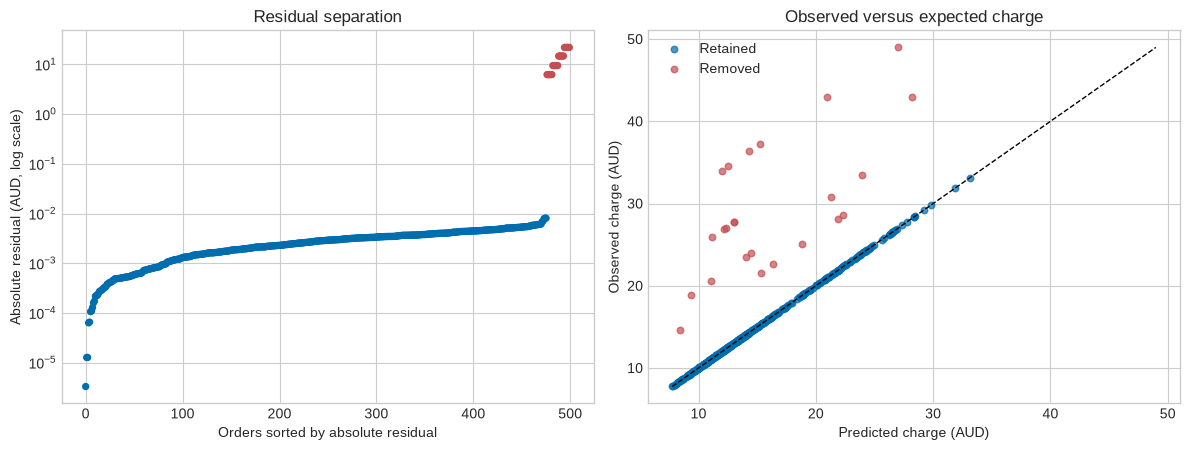

In [28]:
residuals = outlier_result.residual_diagnostics.sort_values("absolute_residual").reset_index(drop=True)
colours = np.where(residuals["remove_as_outlier"], "#c44e52", "#006dae")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].scatter(np.arange(len(residuals)), residuals["absolute_residual"], c=colours, s=18)
axes[0].set_yscale("log")
axes[0].set_xlabel("Orders sorted by absolute residual")
axes[0].set_ylabel("Absolute residual (AUD, log scale)")
axes[0].set_title("Residual separation")

for removed, group in residuals.groupby("remove_as_outlier"):
    axes[1].scatter(
        group["predicted_delivery_charge"],
        group["observed_delivery_charge"],
        label="Removed" if removed else "Retained",
        color="#c44e52" if removed else "#006dae",
        alpha=0.7,
        s=22,
    )
line_min = residuals[["predicted_delivery_charge", "observed_delivery_charge"]].min().min()
line_max = residuals[["predicted_delivery_charge", "observed_delivery_charge"]].max().max()
axes[1].plot([line_min, line_max], [line_min, line_max], "k--", linewidth=1)
axes[1].set_xlabel("Predicted charge (AUD)")
axes[1].set_ylabel("Observed charge (AUD)")
axes[1].set_title("Observed versus expected charge")
axes[1].legend()

plt.tight_layout()
plt.show()

In [29]:
removed_rows = residuals.loc[residuals["remove_as_outlier"]]
retained_rows = residuals.loc[~residuals["remove_as_outlier"]]

outlier_summary = pd.DataFrame(
    {
        "metric": [
            "input rows",
            "removed rows",
            "retained rows",
            "maximum retained absolute residual",
            "minimum removed absolute residual",
            "separation ratio",
        ],
        "value": [
            len(outlier_raw),
            len(removed_rows),
            len(retained_rows),
            retained_rows["absolute_residual"].max(),
            removed_rows["absolute_residual"].min(),
            removed_rows["absolute_residual"].min() / retained_rows["absolute_residual"].max(),
        ],
    }
)
display(outlier_summary)
display(removed_rows.sort_values("absolute_residual", ascending=False).head(10))

,metric,value
0,input rows,500.000000
1,removed rows,24.000000
2,retained rows,476.000000
3,maximum retained absolute residual,0.008065
4,minimum removed absolute residual,6.245964
5,separation ratio,774.417115


,order_id,season,observed_delivery_charge,predicted_delivery_charge,residual,absolute_residual,residual_threshold,remove_as_outlier
499,CORD001247,Autumn,33.98,11.975584,22.004416,22.004416,0.015942,True
498,CORD001435,Winter,36.33,14.326444,22.003556,22.003556,0.015577,True
497,CORD001099,Summer,37.25,15.249360,22.000640,22.000640,0.015764,True
496,CORD001163,Spring,42.95,20.949916,22.000084,22.000084,0.015915,True
495,CORD001259,Winter,48.98,26.983040,21.996960,21.996960,0.015577,True
494,CORD001063,Autumn,34.52,12.523534,21.996466,21.996466,0.015942,True
493,CORD001258,Autumn,27.76,13.006433,14.753567,14.753567,0.015942,True
492,CORD001478,Spring,27.05,12.296699,14.753301,14.753301,0.015915,True
491,CORD001158,Summer,26.94,12.189373,14.750627,14.750627,0.015764,True
490,CORD001058,Winter,42.96,28.209584,14.750416,14.750416,0.015577,True


Twenty-four rows exceed their seasonal thresholds and are removed rather than repaired. The maximum retained residual is approximately AUD 0.0081, while the minimum removed residual is approximately AUD 6.246—a separation ratio above 770. This large empirical gap protects expensive but model-consistent deliveries from deletion.

For example, CORD001017 has an observed Spring charge of 23.97, prediction 14.4692, absolute residual 9.5008 and threshold approximately 0.0159. The audit log records `delivery_charges`, the original value and `ROW_REMOVED`; no estimated charge is substituted.

## 5.2 Outlier-output validation

Validation reconciles 500 input rows with 476 retained and 24 removed IDs, verifies every retained cell against its source value, checks all retained business relationships and confirms that every removal has one matching `outlier_row` audit record.

In [30]:
display(outlier_result.validation)
assert outlier_result.validation["passed"].all()

,check,observed_result,passed,interpretation
0,schema_and_column_order,"[order_id, customer_id, date, nearest_warehous...",True,Output uses the exact required 16-column schema.
1,input_output_row_reconciliation,"{'input_rows': 500, 'removed_rows': 24, 'retai...",True,Input rows equal removed plus retained rows.
2,unique_retained_order_ids,476,True,Retained IDs remain unique.
3,retained_order_id_set,"{'missing': 0, 'unexpected': 0}",True,Output contains exactly the model-rule retaine...
4,required_completeness,0,True,No missing values were introduced.
5,preservation_of_retained_values,0,True,Every retained field is equal in meaning to it...
6,residual_rule_reconciliation,"{'retained_rule_failures': 0, 'removed_rule_fa...",True,Every removal and retention agrees with its se...
7,residual_separation,{'maximum_retained_absolute_residual': 0.00806...,True,Removed rows form a clearly separated residual...
8,shopping_cart_structure,True,True,Retained carts are valid JSON arrays.
9,order_price_relationship,0.0,True,Cart equations reproduce retained prices.


All outlier checks pass. The 476 retained rows have zero field-level differences from their source records; row removal is the only operation applied to this batch.

# 6. Audit trail and final validation

The audit trail is created at the moment a workflow change is applied and is then reconciled against actual source/output differences. It uses the exact required column order and contains no unchanged fields or Task 3 transformations.

**Confidence definitions**

- **High:** an exact published relationship identifies a unique value, or a held-out validated model produces a clearly separated decision.
- **Medium:** defensible model evidence exists, but residual separation or corroborating evidence is weaker.
- **Low:** material ambiguity remains and must be explicitly disclosed.

All current Group030 decisions are high confidence.

In [31]:
audit_log = pd.read_csv(AUDIT_OUTPUT, keep_default_na=False)
assert list(audit_log.columns) == [
    "source_file",
    "record_key",
    "field_name",
    "issue_type",
    "original_value",
    "corrected_value",
    "method",
    "evidence",
    "confidence",
]

audit_summary = (
    audit_log.groupby(["source_file", "issue_type", "field_name", "confidence"], as_index=False)
    .size()
    .rename(columns={"size": "audit_rows"})
)
print("Total audit rows:", len(audit_log))
display(audit_summary)

Total audit rows: 184


,source_file,issue_type,field_name,confidence,audit_rows
0,Group030_dirty_data.csv,dirty,customer_lat,high,8
1,Group030_dirty_data.csv,dirty,date,high,8
2,Group030_dirty_data.csv,dirty,delivery_charges,high,8
3,Group030_dirty_data.csv,dirty,distance_to_nearest_warehouse,high,8
4,Group030_dirty_data.csv,dirty,is_expedited_delivery,high,8
5,Group030_dirty_data.csv,dirty,is_happy_customer,high,8
6,Group030_dirty_data.csv,dirty,nearest_warehouse,high,8
7,Group030_dirty_data.csv,dirty,order_price,high,8
8,Group030_dirty_data.csv,dirty,order_total,high,8
9,Group030_dirty_data.csv,dirty,season,high,8


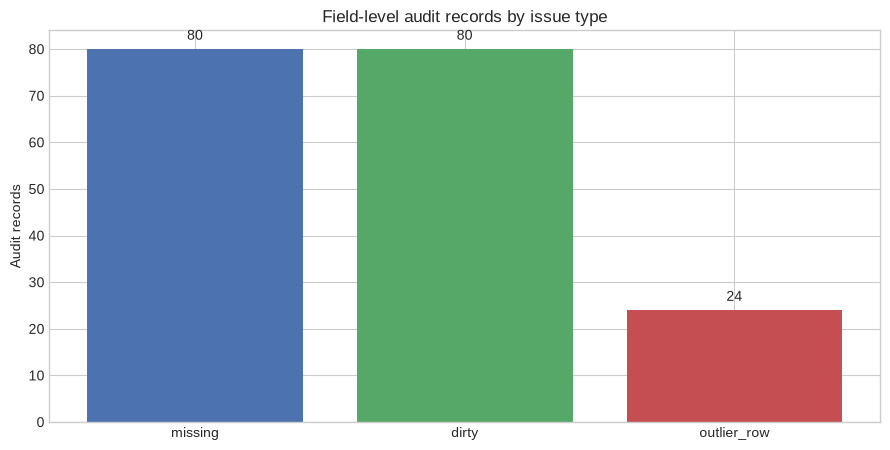

,source_file,record_key,field_name,issue_type,original_value,corrected_value,method,evidence,confidence
0,Group030_missing_data.csv,CORD000594,season,missing,<MISSING>,Summer,Australian season derived from order-date month,M01: published month-to-season mapping,high
1,Group030_missing_data.csv,CORD000610,season,missing,<MISSING>,Summer,Australian season derived from order-date month,M01: published month-to-season mapping,high
2,Group030_missing_data.csv,CORD000652,season,missing,<MISSING>,Autumn,Australian season derived from order-date month,M01: published month-to-season mapping,high
80,Group030_dirty_data.csv,CORD000007,is_happy_customer,dirty,False,True,Apply frozen local VADER compound threshold an...,D07: verified lexicon; compound >= 0.05,high
81,Group030_dirty_data.csv,CORD000017,nearest_warehouse,dirty,THOMPSON WH,Thompson,Select minimum Haversine distance to supplied ...,"D04: 6,371 km Haversine comparison and canonic...",high
82,Group030_dirty_data.csv,CORD000035,nearest_warehouse,dirty,THOMPSON WH,Thompson,Select minimum Haversine distance to supplied ...,"D04: 6,371 km Haversine comparison and canonic...",high
160,Group030_outlier_data.csv,CORD001017,delivery_charges,outlier_row,23.97,ROW_REMOVED,Remove row when seasonal-model absolute residu...,"O01: Spring observed=23.97, predicted=14.4692,...",high
161,Group030_outlier_data.csv,CORD001040,delivery_charges,outlier_row,28.12,ROW_REMOVED,Remove row when seasonal-model absolute residu...,"O01: Summer observed=28.12, predicted=21.8660,...",high
162,Group030_outlier_data.csv,CORD001057,delivery_charges,outlier_row,20.55,ROW_REMOVED,Remove row when seasonal-model absolute residu...,"O01: Autumn observed=20.55, predicted=11.0495,...",high


In [32]:
fig, ax = plt.subplots(figsize=(9, 4.6))
issue_counts = audit_log["issue_type"].value_counts().reindex(["missing", "dirty", "outlier_row"])
ax.bar(issue_counts.index, issue_counts.values, color=["#4c72b0", "#55a868", "#c44e52"])
for position, value in enumerate(issue_counts.values):
    ax.text(position, value + 2, str(value), ha="center")
ax.set_ylabel("Audit records")
ax.set_title("Field-level audit records by issue type")
plt.tight_layout()
plt.show()

display(audit_log.groupby("issue_type", group_keys=False).head(3))

The final log contains 80 missing replacements, 80 dirty repairs and 24 outlier-row removals, for 184 records in total. Missing source values use `<MISSING>`, and removed rows use `ROW_REMOVED`.

## 6.1 Consolidated validation evidence

The following table combines every executable check returned by the three workflows. A pass count alone is not treated as proof; the preceding sections expose the observed values and interpretations behind each result.

In [33]:
all_validation = pd.concat(
    [
        missing_result.validation.assign(batch="missing"),
        dirty_result.validation.assign(batch="dirty"),
        outlier_result.validation.assign(batch="outlier"),
    ],
    ignore_index=True,
)
validation_summary = (
    all_validation.groupby("batch")["passed"]
    .agg(checks="size", passed="sum")
    .reset_index()
)
validation_summary["failed"] = validation_summary["checks"] - validation_summary["passed"]
display(validation_summary)
assert all_validation["passed"].all()

,batch,checks,passed,failed
0,dirty,18,18,0
1,missing,15,15,0
2,outlier,17,17,0


In [34]:
output_paths = {
    "dirty_clean": DIRTY_OUTPUT,
    "missing_clean": MISSING_OUTPUT,
    "outlier_clean": OUTLIER_OUTPUT,
    "audit_log": AUDIT_OUTPUT,
}
output_summary = []
for label, path in output_paths.items():
    frame = pd.read_csv(path, keep_default_na=False)
    output_summary.append(
        {
            "output": label,
            "filename": path.name,
            "rows": len(frame),
            "columns": frame.shape[1],
            "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
        }
    )
display(pd.DataFrame(output_summary))

,output,filename,rows,columns,sha256
0,dirty_clean,Group030_dirty_clean.csv,500,16,28a62e53917f0b2230d4c820f22819d3967ed606c8fcee...
1,missing_clean,Group030_missing_clean.csv,500,16,e0ce24754c1de8cb5b6851c694d9d858ed42b91104cfa5...
2,outlier_clean,Group030_outlier_clean.csv,476,16,b68b7709d301538040022f53decc77a61a558f6d3359f8...
3,audit_log,audit_log.csv,184,9,f6b1ec97af9eecf72a9f75be6d14ee3df03b5c50d9260d...


The three required cleaned CSVs and audit log are readable from disk. Dirty and missing each retain 500 orders; outlier retains 476. Output hashes provide a reproducibility fingerprint, while the relationship and preservation tests establish substantive correctness.

# 7. Customer profiling and transformation

Task 3 uses a separate analysis copy built only from the three submitted cleaned CSVs. Removed outlier orders are not restored. These profiles describe retained A2 activity, not complete customer histories or lifetime value.

In [35]:
cleaned_paths = {
    "dirty": DIRTY_OUTPUT,
    "missing": MISSING_OUTPUT,
    "outlier": OUTLIER_OUTPUT,
}
cleaned_frames = []
for source_batch, path in cleaned_paths.items():
    frame = pd.read_csv(path, **read_options)
    frame["source_batch"] = source_batch
    cleaned_frames.append(frame)

profile_orders = pd.concat(cleaned_frames, ignore_index=True)
profile_input_summary = pd.DataFrame(
    {
        "source_batch": list(cleaned_paths),
        "retained_rows": [len(frame) for frame in cleaned_frames],
    }
)
display(profile_input_summary)
print("Combined distinct orders:", profile_orders["order_id"].nunique())
print("Customers represented:", profile_orders["customer_id"].nunique())

,source_batch,retained_rows
0,dirty,500
1,missing,500
2,outlier,476


Combined distinct orders: 1476
Customers represented: 471


The analytical copy contains 1,476 distinct retained orders and 471 customers. Source-batch identity remains available for traceability, but aggregation is performed at `customer_id` grain.

## 7.1 Customer-level attributes

Four candidate attributes are derived, after which three are selected for distance-based comparison:

- `order_count`: activity frequency;
- `mean_order_value`: typical paid amount, including discounted items and delivery;
- `mean_delivery_distance`: delivery geography.

`total_paid` is calculated for transparency but not selected. Excluding it avoids the exact dependence `total_paid = order_count × mean_order_value`, which would repeatedly weight purchasing information in Euclidean distance.

In [36]:
customer_profiles = (
    profile_orders.groupby("customer_id", as_index=False)
    .agg(
        order_count=("order_id", "nunique"),
        total_paid=("order_total", "sum"),
        mean_order_value=("order_total", "mean"),
        mean_delivery_distance=("distance_to_nearest_warehouse", "mean"),
    )
)
selected_attributes = ["order_count", "mean_order_value", "mean_delivery_distance"]
baseline_profiles = customer_profiles[["customer_id", *selected_attributes]].copy()

display(customer_profiles.head())
display(baseline_profiles[selected_attributes].describe().T)

,customer_id,order_count,total_paid,mean_order_value,mean_delivery_distance
0,CUS00001,3,12257.60,4085.866667,4.1886
1,CUS00002,2,8586.37,4293.185000,3.5348
2,CUS00003,1,5210.66,5210.660000,7.7936
3,CUS00005,5,28407.04,5681.408000,8.5114
4,CUS00006,3,13394.31,4464.770000,5.1893


,count,mean,std,min,25%,50%,75%,max
order_count,471.0,3.133758,1.590245,1.0000,2.00000,3.000000,4.00000,10.0000
mean_order_value,471.0,4240.260855,1570.159254,815.5800,3218.19125,4134.523333,5052.62800,11497.8000
mean_delivery_distance,471.0,5.350370,2.177862,0.4852,3.85005,5.525300,7.05705,10.1316


## 7.2 Original scales, distributions and relationships

Without scaling, the monetary attribute would dominate distance calculations because its numerical range is measured in thousands of dollars, whereas count and distance are single-digit quantities.

In [37]:
distribution_summary = pd.DataFrame(
    {
        "minimum": baseline_profiles[selected_attributes].min(),
        "median": baseline_profiles[selected_attributes].median(),
        "mean": baseline_profiles[selected_attributes].mean(),
        "maximum": baseline_profiles[selected_attributes].max(),
        "standard_deviation": baseline_profiles[selected_attributes].std(ddof=1),
        "skewness": baseline_profiles[selected_attributes].skew(),
        "zeros": (baseline_profiles[selected_attributes] == 0).sum(),
    }
)
display(distribution_summary.round(4))

,minimum,median,mean,maximum,standard_deviation,skewness,zeros
order_count,1.0000,3.0000,3.1338,10.0000,1.5902,0.8793,0
mean_order_value,815.5800,4134.5233,4240.2609,11497.8000,1570.1593,0.9282,0
mean_delivery_distance,0.4852,5.5253,5.3504,10.1316,2.1779,-0.2357,0


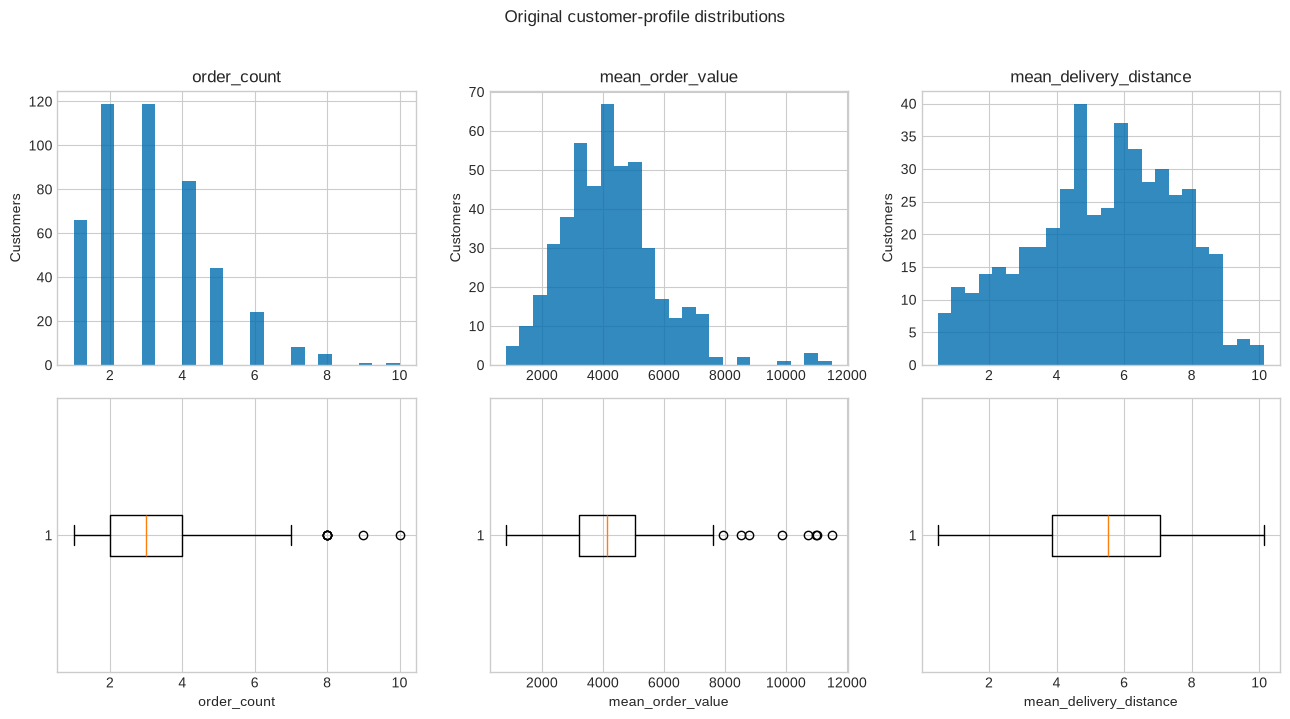

,order_count,mean_order_value,mean_delivery_distance
order_count,1.000,0.092,-0.009
mean_order_value,0.092,1.000,0.026
mean_delivery_distance,-0.009,0.026,1.000


In [38]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for index, attribute in enumerate(selected_attributes):
    axes[0, index].hist(baseline_profiles[attribute], bins=24, color="#006dae", alpha=0.8)
    axes[0, index].set_title(attribute)
    axes[0, index].set_ylabel("Customers")
    axes[1, index].boxplot(baseline_profiles[attribute], orientation="horizontal")
    axes[1, index].set_xlabel(attribute)
plt.suptitle("Original customer-profile distributions", y=1.02)
plt.tight_layout()
plt.show()

correlations = baseline_profiles[selected_attributes].corr()
display(correlations.round(3))

`order_count` is discrete and moderately right-skewed; `mean_order_value` is also right-skewed; `mean_delivery_distance` is only mildly left-skewed. Pairwise correlations among the selected attributes are small, so the selection avoids the strong activity/spending redundancy that would arise from using count, total and mean together.

## 7.3 Standardisation and min-max scaling

Both required scaling approaches are fitted to the three selected attributes:

\[
z=(x-\mu)/\sigma, \qquad x'=(x-\min x)/(\max x-\min x).
\]

Z-score standardisation expresses variation in standard-deviation units. Min-max scaling constrains each feature to `[0,1]` but can compress typical observations when an extreme defines the range.

In [39]:
z_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

z_scaled = pd.DataFrame(
    z_scaler.fit_transform(baseline_profiles[selected_attributes]),
    columns=[f"{column}_z" for column in selected_attributes],
    index=baseline_profiles.index,
)
minmax_scaled = pd.DataFrame(
    minmax_scaler.fit_transform(baseline_profiles[selected_attributes]),
    columns=[f"{column}_minmax" for column in selected_attributes],
    index=baseline_profiles.index,
)

scaling_comparison = pd.DataFrame(
    {
        "original_range": baseline_profiles[selected_attributes].max() - baseline_profiles[selected_attributes].min(),
        "z_mean": z_scaled.mean().to_numpy(),
        "z_std_population": z_scaled.std(ddof=0).to_numpy(),
        "minmax_min": minmax_scaled.min().to_numpy(),
        "minmax_max": minmax_scaled.max().to_numpy(),
    },
    index=selected_attributes,
)
display(scaling_comparison.round(6))

,original_range,z_mean,z_std_population,minmax_min,minmax_max
order_count,9.0000,-0.0,1.0,0.0,1.0
mean_order_value,10682.2200,0.0,1.0,0.0,1.0
mean_delivery_distance,9.6464,-0.0,1.0,0.0,1.0


Both methods remove unit differences. Z-score scaling centres each attribute at zero with population standard deviation one; min-max maps observed endpoints to zero and one. Neither method removes skewness, and both remain influenced by extreme observations in different ways.

## 7.4 Nonlinear transformation comparison

`mean_order_value` is strictly positive, so square-root and `log1p` transformations are both defined. They are compared against the original rather than assumed to be beneficial. If a nonlinear transform is recommended, it is applied before scaling.

,skewness,minimum,median,maximum
original,0.9282,815.5800,4134.5233,11497.8000
square_root,0.1560,28.5584,64.3003,107.2278
log1p,-0.5920,6.7051,8.3274,9.3500


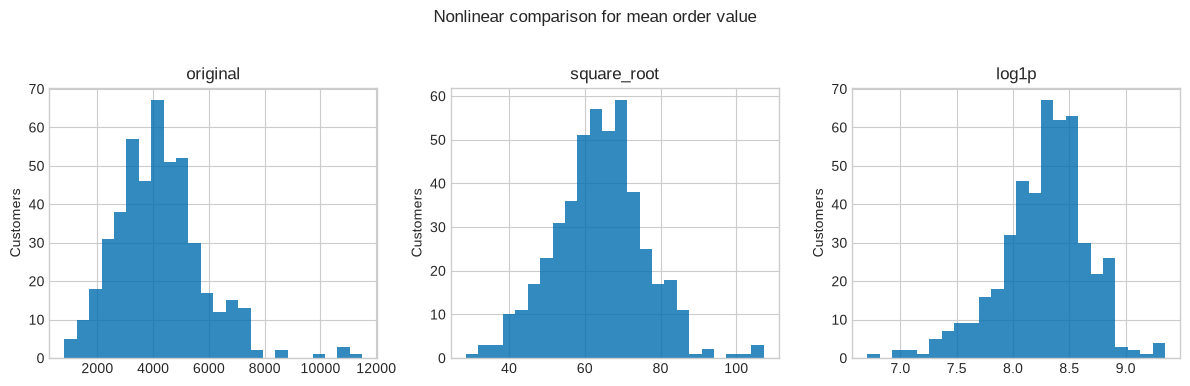

In [40]:
nonlinear_comparison = pd.DataFrame(
    {
        "original": baseline_profiles["mean_order_value"],
        "square_root": np.sqrt(baseline_profiles["mean_order_value"]),
        "log1p": np.log1p(baseline_profiles["mean_order_value"]),
    }
)
nonlinear_summary = pd.DataFrame(
    {
        "skewness": nonlinear_comparison.skew(),
        "minimum": nonlinear_comparison.min(),
        "median": nonlinear_comparison.median(),
        "maximum": nonlinear_comparison.max(),
    }
)
display(nonlinear_summary.round(4))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.7))
for axis, column in zip(axes, nonlinear_comparison.columns):
    axis.hist(nonlinear_comparison[column], bins=24, color="#006dae", alpha=0.8)
    axis.set_title(column)
    axis.set_ylabel("Customers")
plt.suptitle("Nonlinear comparison for mean order value", y=1.03)
plt.tight_layout()
plt.show()

The square-root transformation reduces `mean_order_value` skewness from approximately 0.93 to 0.16 while retaining more separation among high-spending customers than `log1p`, which reverses the skew to approximately −0.59. Normality is not the objective; the square root is preferred here because it moderates extreme monetary influence without excessive compression.

## 7.5 Recommended analytical treatment

The recommended analysis copy is constructed only in memory. Customer IDs are not transformed, and no transformed value is written to a cleaned CSV or audit record.

In [41]:
recommended_base = pd.DataFrame(
    {
        "order_count": baseline_profiles["order_count"],
        "mean_order_value": np.sqrt(baseline_profiles["mean_order_value"]),
        "mean_delivery_distance": baseline_profiles["mean_delivery_distance"],
    }
)
recommended_scaler = StandardScaler()
recommended_scaled = pd.DataFrame(
    recommended_scaler.fit_transform(recommended_base),
    columns=[f"{column}_recommended" for column in recommended_base.columns],
)
recommended_profiles = pd.concat(
    [baseline_profiles[["customer_id"]], recommended_scaled], axis=1
)

recommendations = pd.DataFrame(
    [
        {
            "attribute": "order_count",
            "methods_compared": "original, z-score, min-max; log1p reviewed",
            "observed_effect": "Discrete range 1–10; moderate skew; no severe scale outlier",
            "recommended_treatment": "no nonlinear transformation; z-score standardisation",
            "justification_or_limitation": "Preserves count interpretation before scaling; profiles cover retained A2 orders only",
        },
        {
            "attribute": "mean_order_value",
            "methods_compared": "original, square root, log1p, z-score, min-max",
            "observed_effect": "Square root reduces skew from about 0.93 to 0.16; log1p over-compresses the upper tail",
            "recommended_treatment": "square root first; then z-score standardisation",
            "justification_or_limitation": "Reduces extreme monetary dominance; transformed units are less directly interpretable",
        },
        {
            "attribute": "mean_delivery_distance",
            "methods_compared": "original, z-score, min-max; nonlinear transformation reviewed",
            "observed_effect": "Mild negative skew and bounded positive range; nonlinear transforms increase asymmetry",
            "recommended_treatment": "no nonlinear transformation; z-score standardisation",
            "justification_or_limitation": "Retains kilometre ordering before scaling; straight-line distance is not travel time",
        },
    ]
)
display(recommendations)
display(recommended_profiles.head())

,attribute,methods_compared,observed_effect,recommended_treatment,justification_or_limitation
0,order_count,"original, z-score, min-max; log1p reviewed",Discrete range 1–10; moderate skew; no severe ...,no nonlinear transformation; z-score standardi...,Preserves count interpretation before scaling;...
1,mean_order_value,"original, square root, log1p, z-score, min-max",Square root reduces skew from about 0.93 to 0....,square root first; then z-score standardisation,Reduces extreme monetary dominance; transforme...
2,mean_delivery_distance,"original, z-score, min-max; nonlinear transfor...",Mild negative skew and bounded positive range;...,no nonlinear transformation; z-score standardi...,Retains kilometre ordering before scaling; str...


,customer_id,order_count_recommended,mean_order_value_recommended,mean_delivery_distance_recommended
0,CUS00001,-0.084201,-0.007720,-0.534012
1,CUS00002,-0.713704,0.126401,-0.834534
2,CUS00003,-1.343206,0.684329,1.123041
3,CUS00005,1.174804,0.951483,1.452981
4,CUS00006,-0.084201,0.234975,-0.074036


Z-score standardisation is recommended consistently so each retained feature contributes on a comparable variance scale. The nonlinear decision is attribute-specific: no transform for count or distance, and square root before standardisation for mean order value. These comparisons prepare features for possible future distance-based exploration; they do not establish that meaningful customer clusters exist.

# 8. Reproducibility and submission checklist

- [x] Three cleaned CSVs use the exact 16-column schema and required row rules.  
- [x] `audit_log.csv` reconciles every imputation, dirty repair and outlier removal.  
- [x] The notebook reads raw inputs from configurable paths and recreates all outputs offline.  
- [x] Product prices and delivery models are evaluated using reproducible held-out evidence.  
- [x] Task 3 reads the final cleaned outputs and keeps transformations in the analysis copy.  
- [x] Confirm the five cover-page member names and student IDs against the signed Assessment 1 group declaration.  
- [ ] Freeze final dependency versions in `requirements.txt` after the group’s clean-environment run.  
- [ ] Export the matching `Group030_solution.py` and include all imported helper modules.  
- [ ] Complete and sign `Group030_AI_declaration.pdf`; include applicable complete AI records and English index.  
- [ ] Assemble `Group030_A2_submission/`, restart the kernel, Run All and inspect the final ZIP.

# References

- FIT5196 Assessment 2 specification, Semester 2 2026.  
- scikit-learn documentation: `LinearRegression`, `StandardScaler` and `MinMaxScaler`.  
- NLTK VADER sentiment analyser, using the supplied frozen local lexicon.  
- Monash University Brand Book, “Our logo”: https://www.monash.edu/brandbook/brand-elements/our-logo  
- Logo image used on the cover: https://images.seeklogo.com/logo-png/34/1/monash-university-logo-png_seeklogo-347063.png

All external code ideas must be cited if added by group members. AI use and independent verification are documented separately in the required declaration and conversation index.